# Control flow and boundary cases

Assign each observation to a band, including the observations exactly on a boundary.

Use three disjoint intervals. Values at or below zero enter the first band. Positive values below 20 enter the second. Everything at or above 20 enters the last band. Summing the band counts gives a conservation check that catches dropped observations, although it cannot by itself detect a misplaced observation.

CASE applies the first matching condition. GROUP BY counts present bands. Join a category table if the application must also return empty bands.

In [1]:
from pathlib import Path
import sys, math, statistics
import numpy as np
import matplotlib.pyplot as plt

here = Path.cwd()
sys.path.insert(0, str(here.parent.parent))
from course_runner import run_native

## Native source

`native.sql`

```sql
WITH readings(x) AS (VALUES (-4), (0), (5), (12), (18), (25), (31)),
labelled AS (
    SELECT CASE WHEN x <= 0 THEN 0 WHEN x < 20 THEN 1 ELSE 2 END AS band
    FROM readings
)
SELECT count(*) FROM labelled GROUP BY band ORDER BY band;
```

## Execute the native listing

CASE applies the first matching condition. GROUP BY counts present bands. Join a category table if the application must also return empty bands. Write down the grain of the result: what does one row represent? Aggregation changes the grain, whereas a window function can attach a result to each input row.

In [2]:
x = [-4, 0, 5, 12, 18, 25, 31]
expected = np.asarray(
    [sum(v <= 0 for v in x), sum(0 < v < 20 for v in x), sum(v >= 20 for v in x)], dtype=float
)
engine, stdout = run_native(here / "native.sql")
observed = np.asarray([float(v) for v in stdout.split()])
assert observed.shape == expected.shape
np.testing.assert_allclose(observed, expected, rtol=2e-7, atol=2e-7)
print("Runtime:", engine)
print("Native stdout:", stdout.strip())
print("Largest absolute difference:", f"{np.max(np.abs(observed-expected)):.3g}")

Runtime: SQLite
Native stdout: 2 3 2
Largest absolute difference: 0


## Read the output

Read each bar as a count. A boundary convention is part of the specification and should be stated before choosing the test inputs. The marks show the independent Python reference at each position.

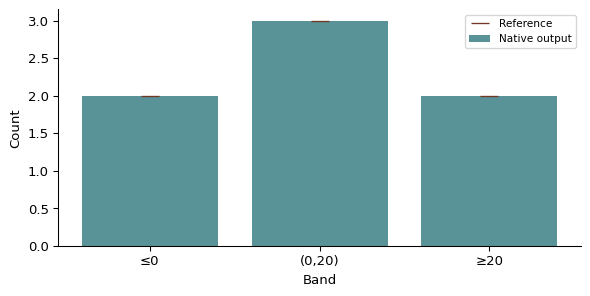

In [3]:
labels = ["≤0", "(0,20)", "≥20"]
positions = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(6.1, 3), constrained_layout=True)
ax.bar(positions, observed, color="#367b80", alpha=0.82, label="Native output")
ax.plot(
    positions,
    expected,
    linestyle="none",
    marker="_",
    markersize=13,
    color="#713925",
    label="Reference",
)
ax.set(xticks=positions, xticklabels=labels, xlabel="Band", ylabel="Count")
ax.legend(fontsize=8)
plt.show()

## Interpreting the result

Read each bar as a count. A boundary convention is part of the specification and should be stated before choosing the test inputs.

## Exercise

Add values 19 and 20, then predict which two bars change. Test a list that leaves a category empty.

## References

[SQLite, SQL language documentation](https://sqlite.org/lang.html)

[SQLite, window frames](https://sqlite.org/windowfunctions.html)